In [8]:
import numpy as np
import os
import matplotlib.pyplot as plt

dataset_folder = "datasets"
table_test = np.load(os.path.join(dataset_folder, "ratings_test.npy"))
namesngenre = np.load(os.path.join(dataset_folder, "namesngenre.npy"))
table_train = np.load(os.path.join(dataset_folder, "ratings_train.npy"))

In [9]:
namesngenre

array([['Toy Story (1995)',
        'Adventure|Animation|Children|Comedy|Fantasy'],
       ['Jumanji (1995)', 'Adventure|Children|Fantasy'],
       ['Grumpier Old Men (1995)', 'Comedy|Romance'],
       ...,
       ['Elsa & Fred (2005)', 'Comedy|Drama|Romance'],
       ['Tomb Raider (2018)', 'Action|Adventure|Fantasy'],
       ['Fred Armisen: Standup for Drummers (2018)', 'Comedy']],
      shape=(4980, 2), dtype='<U158')

In [10]:
table_test

array([[nan, nan,  4., ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       ...,
       [nan, nan,  2., ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [ 5., nan, nan, ..., nan, nan, nan]], shape=(610, 4980))

In [11]:
table_train

array([[ 4., nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       ...,
       [nan,  2., nan, ..., nan, nan, nan],
       [ 3., nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan]], shape=(610, 4980))

In [12]:
total_nans = np.count_nonzero(~np.isnan(table_train))
print("Number of not empty entries in the train set :", total_nans)

total_nb_cells = table_train.size
print(f"Proportion of empty entries : {(1 - total_nans/ total_nb_cells)*100:.3f}%")

Number of not empty entries in the train set : 31598
Proportion of empty entries : 98.960%


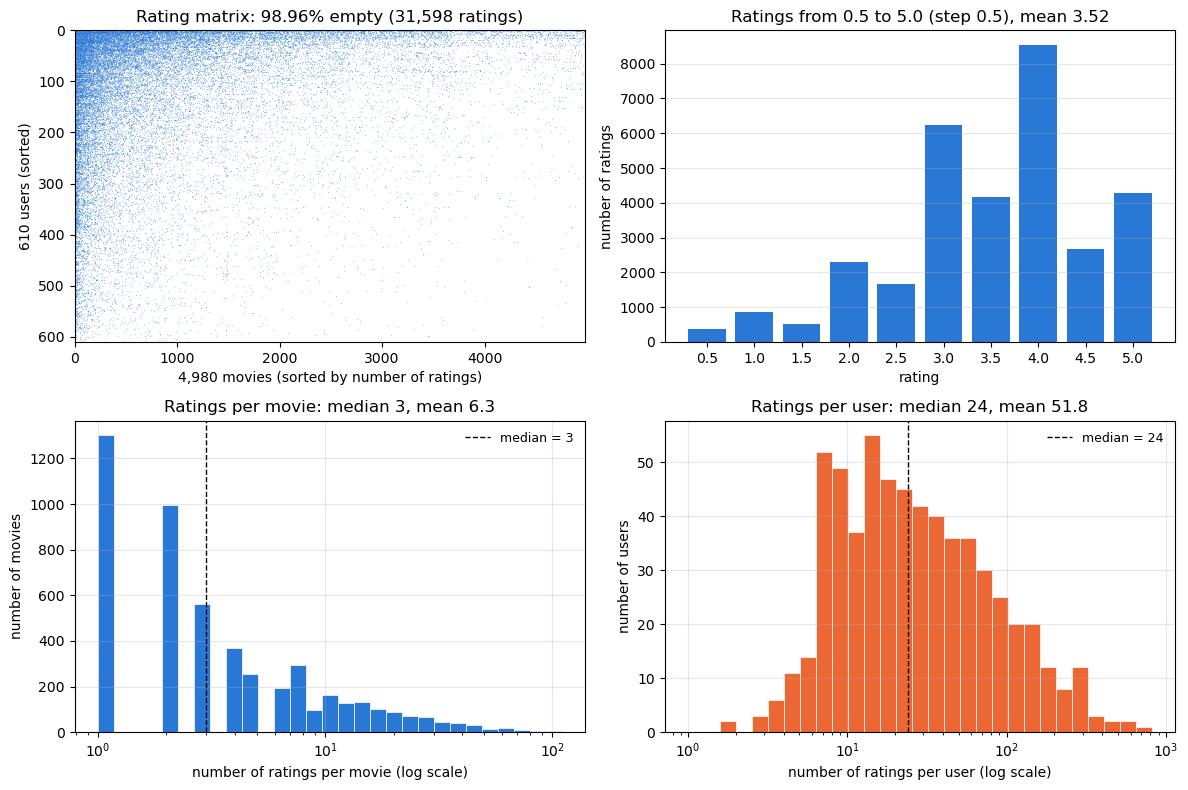

In [13]:
# Dataset overview (all of ratings_train): sparsity, rating values, ratings per movie and per user
obs = ~np.isnan(table_train)                     # users x movies
n_users, n_movies = obs.shape
per_movie = obs.sum(axis=0)
per_user = obs.sum(axis=1)
values = table_train[obs]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# 1. the matrix itself: one dot per known rating, users and movies sorted by activity
ax = axes[0, 0]
M = obs[np.argsort(-per_user)][:, np.argsort(-per_movie)]
u, m = np.nonzero(M)
ax.scatter(m, u, s=0.3, color="#2a78d6", edgecolors="none")
ax.set_xlim(0, n_movies)
ax.set_ylim(n_users, 0)
ax.set_xlabel(f"{n_movies:,} movies (sorted by number of ratings)")
ax.set_ylabel(f"{n_users} users (sorted)")
ax.set_title(f"Rating matrix: {100 * (1 - obs.mean()):.2f}% empty ({obs.sum():,} ratings)")

# 2. rating values
ax = axes[0, 1]
levels, counts = np.unique(values, return_counts=True)
ax.bar(levels, counts, width=0.4, color="#2a78d6")
ax.set_xticks(levels)
ax.set_xlabel("rating")
ax.set_ylabel("number of ratings")
ax.set_title(f"Ratings from {values.min()} to {values.max()} (step 0.5), mean {values.mean():.2f}")
ax.grid(alpha=0.3, axis="y")

# 3-4. ratings per movie and per user, with the median
for ax, n, name, c in [(axes[1, 0], per_movie, "movie", "#2a78d6"),
                       (axes[1, 1], per_user, "user", "#eb6834")]:
    bins = np.logspace(0, np.log10(n.max() + 1), 30)
    ax.hist(n, bins=bins, color=c, edgecolor="white", linewidth=0.5)
    ax.axvline(np.median(n), color="black", ls="--", lw=1, label=f"median = {np.median(n):.0f}")
    ax.set_xscale("log")
    ax.set_xlabel(f"number of ratings per {name} (log scale)")
    ax.set_ylabel(f"number of {name}s")
    ax.set_title(f"Ratings per {name}: median {np.median(n):.0f}, mean {n.mean():.1f}")
    ax.legend(frameon=False, fontsize=9)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

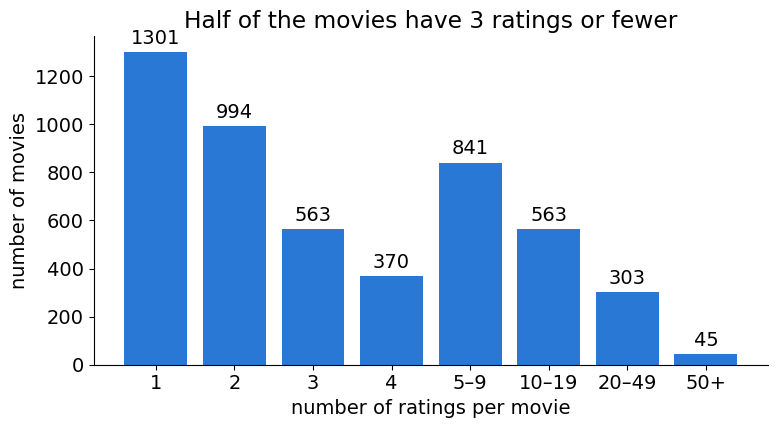

In [16]:
import numpy as np, matplotlib.pyplot as plt

n_per_movie = (~np.isnan(table_train)).sum(axis=0)        # table_train is users x movies
edges  = [1, 2, 3, 4, 5, 10, 20, 50, n_per_movie.max() + 1]
labels = ["1", "2", "3", "4", "5–9", "10–19", "20–49", "50+"]
counts = [((n_per_movie >= a) & (n_per_movie < b)).sum() for a, b in zip(edges[:-1], edges[1:])]

plt.rcParams["font.size"] = 14
fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(labels, counts, color="#2a78d6")
ax.bar_label(bars, padding=3)
ax.set_xlabel("number of ratings per movie")
ax.set_ylabel("number of movies")
ax.set_title("Half of the movies have 3 ratings or fewer")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("ratings_per_movie.png", dpi=200)

In [14]:
R = table_train.T                          # items × users
observed = ~np.isnan(R)
R0 = np.nan_to_num(R)

# --- 80/20 split of the observed cells ---
rng = np.random.default_rng(42)          # PLAY: seed (rerun with several seeds for mean ± std)
rows, cols = np.where(observed)      # positions of all known ratings
perm = rng.permutation(len(rows))
n_train = int(0.8 * len(rows))           # PLAY: train / validation ratio
tr, vl = perm[:n_train], perm[n_train:]

train_mask = np.zeros_like(observed)
train_mask[rows[tr], cols[tr]] = True
val_mask = np.zeros_like(observed)
val_mask[rows[vl], cols[vl]] = True

mu_train = float(R0[train_mask].mean()) 

items: median 2 ratings (3 without the 0s, as in the plot), mean 5.1, max 89, 6% with 0, 71% with fewer than 5
users: median 19 ratings (19 without the 0s, as in the plot), mean 41.4, max 658, 0% with 0, 5% with fewer than 5


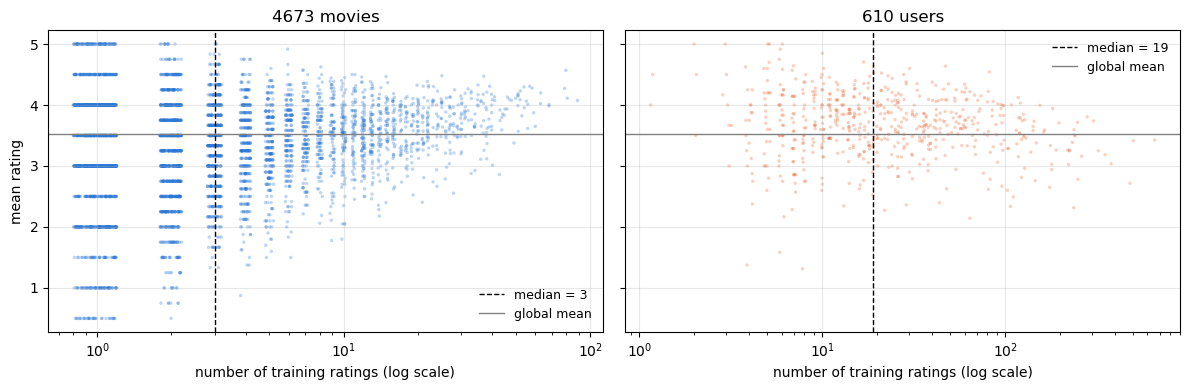

In [15]:
# Ratings per movie and per user (training split)
n_per_item = train_mask.sum(axis=1)              # R is items x users
n_per_user = train_mask.sum(axis=0)
with np.errstate(invalid="ignore"):              # movies with 0 ratings: mean is NaN, skipped below
    mean_item = (R0 * train_mask).sum(axis=1) / n_per_item
    mean_user = (R0 * train_mask).sum(axis=0) / n_per_user

for name, n in [("items", n_per_item), ("users", n_per_user)]:
    print(f"{name}: median {np.median(n):.0f} ratings ({np.median(n[n > 0]):.0f} without the 0s, as in the plot), mean {n.mean():.1f}, max {n.max()}, "
          f"{(n == 0).mean():.0%} with 0, {(n < 5).mean():.0%} with fewer than 5")

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, n, m, name, c in [(axes[0], n_per_item, mean_item, "movies", "#2a78d6"),
                          (axes[1], n_per_user, mean_user, "users", "#eb6834")]:
    keep = n > 0
    jitter = np.random.default_rng(0).uniform(-0.2, 0.2, keep.sum())   # spreads points stacked on 1, 2, 3...
    ax.scatter(n[keep] + jitter, m[keep], s=6, alpha=0.3, color=c, edgecolors="none")
    ax.axvline(np.median(n[keep]), color="black", ls="--", lw=1, label=f"median = {np.median(n[keep]):.0f}")
    ax.axhline(mu_train, color="gray", lw=1, label="global mean")
    ax.set_xscale("log")
    ax.set_xlabel("number of training ratings (log scale)")
    ax.set_title(f"{keep.sum()} {name}")
    ax.legend(frameon=False, fontsize=9)
    ax.grid(alpha=0.3)
axes[0].set_ylabel("mean rating")
plt.tight_layout()
plt.show()

In [14]:
def rmse(mask, pred):
    err = mask * (R0 - pred)
    return np.sqrt((err ** 2).sum() / mask.sum())

# --- training on the 80% only ---
m, n = R.shape
k = 8                                   # PLAY: number of latent factors
lam, mu = 0.1, 0.1                       # PLAY: regularization on I and U
lr = 1e-4                                # PLAY: learning rate (too high -> nan)
n_iter = 1151                             # PLAY: number of iterations

I = rng.normal(0, 0.1, (m, k))           # PLAY: initialization scale
U = rng.normal(0, 0.1, (n, k))

for t in range(n_iter):
    E = train_mask * (R0 - I @ U.T)

    grad_I = -2 * E @ U + 2 * lam * I
    grad_U = -2 * E.T @ I + 2 * mu * U

    I -= lr * grad_I
    U -= lr * grad_U

    if t % 50 == 0:
        pred = I @ U.T
        print(f"iter {t}: train RMSE = {rmse(train_mask, pred):.4f}, "
              f"validation RMSE = {rmse(val_mask, pred):.4f}")

R_hat = np.clip(I @ U.T, 0.5, 5)
print("final validation RMSE:", rmse(val_mask, R_hat))

iter 0: train RMSE = 3.6708, validation RMSE = 3.6804
iter 50: train RMSE = 3.6638, validation RMSE = 3.6795
iter 100: train RMSE = 3.6317, validation RMSE = 3.6610
iter 150: train RMSE = 3.3314, validation RMSE = 3.4200
iter 200: train RMSE = 2.5007, validation RMSE = 2.7048
iter 250: train RMSE = 1.9326, validation RMSE = 2.2236
iter 300: train RMSE = 1.5842, validation RMSE = 1.9354
iter 350: train RMSE = 1.3527, validation RMSE = 1.7555
iter 400: train RMSE = 1.1905, validation RMSE = 1.6381
iter 450: train RMSE = 1.0720, validation RMSE = 1.5579
iter 500: train RMSE = 0.9822, validation RMSE = 1.5011
iter 550: train RMSE = 0.9123, validation RMSE = 1.4599
iter 600: train RMSE = 0.8565, validation RMSE = 1.4295
iter 650: train RMSE = 0.8112, validation RMSE = 1.4067
iter 700: train RMSE = 0.7735, validation RMSE = 1.3895
iter 750: train RMSE = 0.7418, validation RMSE = 1.3766
iter 800: train RMSE = 0.7147, validation RMSE = 1.3668
iter 850: train RMSE = 0.6912, validation RMSE = 1.